In [27]:
# This plots data from FITS headers taken with the LBTI instrument, for the Procyon Fizeau data
# (adapted from plot_fits_header_data_ab_aur.ipynb)

# Created by E.S., 2018 October

In [28]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import glob, os
%matplotlib inline

In [29]:
# stem of csv of FITS header data
stem = './'

In [30]:
df_all = pd.read_csv(stem + 'procyon_fits_header_info.csv', low_memory=False).sort_values(by='FILENAME')

# the csv contains a few test frames from 2024-01-26; keep only the Procyon night (2024-01-31)
df = df_all[df_all['FILENAME'].str.startswith('lm_240131_')].copy().reset_index(drop=True)

# add frame number col (overwrites the one in the csv, for consistency with the filename)
df['FRAMENUM'] = df['FILENAME'].str.extract(r'lm_240131_(\d+)')[0].astype(int)

# frame ranges on 2024-01-31
#   1-500:       Procyon, LMIR_FW2 = ND1.0-T10
#   501-11800:   Procyon, LMIR_FW2 = Open
#   11801-12800: darks (LMIR_FW4 = Blank)
frame_sci_start, frame_sci_end = 1, 11800
frame_dark_start, frame_dark_end = 11801, 12800
frame_nd_end = 500

In [31]:
# helpers for plotting vs UT, with file numbers on a second x-axis across the top

def framenum_to_ut(framenum):
    # UT (hr) at a given (possibly fractional) file number
    return np.interp(framenum, df['FRAMENUM'], df['LBT_UTC'])

def mark_blocks(ax):
    # mark ND-filter/science/dark boundaries
    ax.axvline(x=framenum_to_ut(frame_nd_end + 0.5), color='k', linestyle=':')
    ax.axvline(x=framenum_to_ut(frame_sci_end + 0.5), color='k', linestyle=':')

def add_framenum_axis(ax, step=500):
    # top x-axis labeled with file numbers every `step` frames; call after setting the x-limits of ax
    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())
    framenums = np.arange(step, max(df['FRAMENUM'])+1, step)
    ax_top.set_xticks(framenum_to_ut(framenums))
    ax_top.set_xticklabels(framenums, rotation=90)
    ax_top.set_xlabel('File number')
    return ax_top

In [32]:
df_all.groupby('DATE-OBS')['OBJNAME'].value_counts(dropna=False)

DATE-OBS    OBJNAME    
2024-01-26  Lookup Name       86
            NaN               10
2024-01-31  Procyon        12800
Name: count, dtype: int64

In [33]:
df['OBJNAME'].unique()

<StringArray>
['Procyon']
Length: 1, dtype: str

In [34]:
for thing in df.keys():
    print(thing)

Unnamed: 0
SIMPLE
BITPIX
NAXIS
NAXIS1
NAXIS2
NAXIS3
BZERO
BSCALE
EXTEND
INSTRUME
PARTNER
PID
PI_NAME
PROPID
DIMMFLUX
LBTTEMP
LWIND1S
RWIND1S
SEEING
SMTTAU
WINDDIR
WINDSPD
LCMODES
LGAIN
LLOOPON
LOFFSETX
LOFFSETY
LOFFSETZ
LSLNULL
LSTATUS
LTTMODUL
LWCCDBIN
LWCCDFRQ
RCMODES
RGAIN
RLOOPON
ROFFSETX
ROFFSETY
ROFFSETZ
RSLNULL
RSTATUS
RTTMODUL
RWCCDBIN
RWCCDFRQ
LBT_AIRM
LBT_ALT
LBT_AZ
LBT_DEC
LBT_LST
LBT_LXOS
LBT_LYOS
LBT_PARA
LBT_RA
LBT_RXOS
LBT_RYOS
LBT_UTC
PCJD
AGE_STOP
IL_HORIZ
LMIR_FW1
LMIR_FW2
LMIR_FW3
LMIR_FW4
LM_APWHL
LM_FW25
LM_MAGWL
NCBMDVT
NIC_NAC
NIL_NDFW
NIL_OPW
NIL_PRW
NLDCRC
NLMGTLT
NLNCNC
NLPPLTLT
NLWNTRNS
NMCMSLD
PIL_VERT
COMTTEMP
CPTEMP
CTLRTEMP
DETTEMP
LMRHTPOW
LMRHTSET
LMRHTVAL
LOPTTEMP
LWBCTEMP
UPBCTEMP
FPCAZM
FPCAZS
FPCELM
FPCELS
FPCPISTM
FPCPISTS
PCB1X
PCB1Y
PCBRAD
PCCLOSED
PCFJMPS
PCLAMB1
PCLAMB2
PCLOOPHZ
PCMSNR1
PCMSNR2
PCPHMCS1
PCPHMCS2
PCPHMEN1
PCPHMEN2
PCPHMSN1
PCPHMSN2
PCPHSTD1
PCPHSTD2
PCPLDG
PCPLIG
PCPLPG
PCPLSP01
PCPLSP1
PCSSPER
PCTIPSP
PCTLTSP
SPCTRANS
SPCTRPOS


In [35]:
df['LBT_UTC']

0        6.0706
1        6.0708
2        6.0708
3        6.0708
4        6.0708
          ...  
12795    6.9114
12796    6.9114
12797    6.9114
12798    6.9114
12799    6.9117
Name: LBT_UTC, Length: 12800, dtype: float64

# Display method 1: Simple printing

In [36]:
list(df.keys())

['Unnamed: 0',
 'SIMPLE',
 'BITPIX',
 'NAXIS',
 'NAXIS1',
 'NAXIS2',
 'NAXIS3',
 'BZERO',
 'BSCALE',
 'EXTEND',
 'INSTRUME',
 'PARTNER',
 'PID',
 'PI_NAME',
 'PROPID',
 'DIMMFLUX',
 'LBTTEMP',
 'LWIND1S',
 'RWIND1S',
 'SEEING',
 'SMTTAU',
 'WINDDIR',
 'WINDSPD',
 'LCMODES',
 'LGAIN',
 'LLOOPON',
 'LOFFSETX',
 'LOFFSETY',
 'LOFFSETZ',
 'LSLNULL',
 'LSTATUS',
 'LTTMODUL',
 'LWCCDBIN',
 'LWCCDFRQ',
 'RCMODES',
 'RGAIN',
 'RLOOPON',
 'ROFFSETX',
 'ROFFSETY',
 'ROFFSETZ',
 'RSLNULL',
 'RSTATUS',
 'RTTMODUL',
 'RWCCDBIN',
 'RWCCDFRQ',
 'LBT_AIRM',
 'LBT_ALT',
 'LBT_AZ',
 'LBT_DEC',
 'LBT_LST',
 'LBT_LXOS',
 'LBT_LYOS',
 'LBT_PARA',
 'LBT_RA',
 'LBT_RXOS',
 'LBT_RYOS',
 'LBT_UTC',
 'PCJD',
 'AGE_STOP',
 'IL_HORIZ',
 'LMIR_FW1',
 'LMIR_FW2',
 'LMIR_FW3',
 'LMIR_FW4',
 'LM_APWHL',
 'LM_FW25',
 'LM_MAGWL',
 'NCBMDVT',
 'NIC_NAC',
 'NIL_NDFW',
 'NIL_OPW',
 'NIL_PRW',
 'NLDCRC',
 'NLMGTLT',
 'NLNCNC',
 'NLPPLTLT',
 'NLWNTRNS',
 'NMCMSLD',
 'PIL_VERT',
 'COMTTEMP',
 'CPTEMP',
 'CTLRTEMP',
 'DETTEMP

In [37]:
for index, row in df[11790:11810].iterrows():
    print("{:<22} {:<8.2f} {:<8.2f} {:<10} {:<10} {:<10} {:<10} {:<12} {:<4}".format(row['FILENAME'], 15*row['LBT_RA'], row['LBT_DEC'], row['LBT_UTC'], row['LMIR_FW2'], row['LM_FW25'], row['LMIR_FW3'], row['LMIR_FW4'], row['PCCLOSED']))

lm_240131_011791.fits  114.82   5.22     6.7914     Open       Open       Open       Br-Alpha-On  0   
lm_240131_011792.fits  114.82   5.22     6.7914     Open       Open       Open       Br-Alpha-On  0   
lm_240131_011793.fits  114.82   5.22     6.7914     Open       Open       Open       Br-Alpha-On  0   
lm_240131_011794.fits  114.82   5.22     6.7914     Open       Open       Open       Br-Alpha-On  0   
lm_240131_011795.fits  114.82   5.22     6.7914     Open       Open       Open       Br-Alpha-On  0   
lm_240131_011796.fits  114.82   5.22     6.7917     Open       Open       Open       Br-Alpha-On  0   
lm_240131_011797.fits  114.82   5.22     6.7917     Open       Open       Open       Br-Alpha-On  0   
lm_240131_011798.fits  114.82   5.22     6.7917     Open       Open       Open       Br-Alpha-On  0   
lm_240131_011799.fits  114.82   5.22     6.7917     Open       Open       Open       Br-Alpha-On  0   
lm_240131_011800.fits  114.82   5.22     6.7917     Open       Open      

In [38]:
# specific task: make list of science frames (ND filter out) which are phase-loop-closed

selected_rows = df[(df['FRAMENUM'] > frame_nd_end) & (df['FRAMENUM'] <= frame_sci_end)]
selected_rows = selected_rows[selected_rows['PCCLOSED'] == 1]

In [39]:
selected_rows['FILENAME']

500      lm_240131_000501.fits
501      lm_240131_000502.fits
502      lm_240131_000503.fits
503      lm_240131_000504.fits
504      lm_240131_000505.fits
                 ...          
11693    lm_240131_011694.fits
11694    lm_240131_011695.fits
11695    lm_240131_011696.fits
11696    lm_240131_011697.fits
11697    lm_240131_011698.fits
Name: FILENAME, Length: 9394, dtype: str

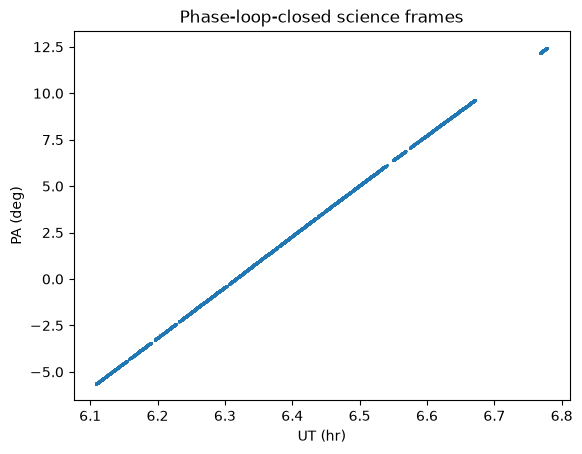

In [ ]:
plt.clf()
plt.scatter(selected_rows['LBT_UTC'], selected_rows['LBT_PARA'], s=1)
plt.xlabel('UT (hr)')
plt.ylabel('PA (deg)')
plt.title('Phase-loop-closed science frames')
plt.show()
#plt.savefig('phase-loop-closed-science-frames.png')

tau_0_min 17.107331083651417
tau_0_max 22.90217486892364
integ time 6.8742


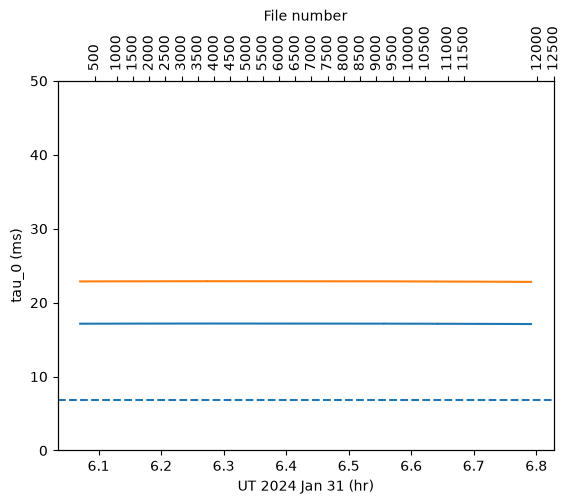

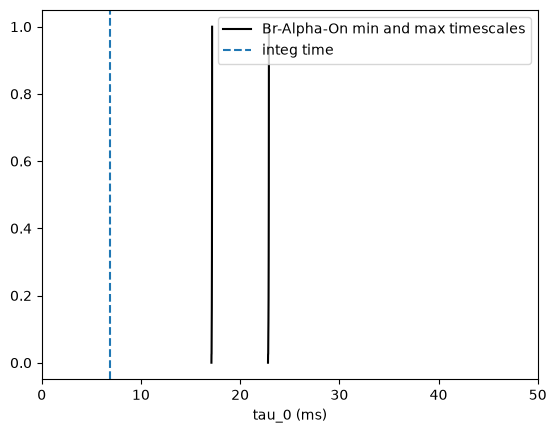

In [41]:
# figure out atmospheric coherence timescale

def tau_0(wavel_um, zenith_deg):
    # defines scaling relation, based on rescalings of tau_0 measured at 1.5 and 2.0 um

    scaler_term = np.power( np.divide(wavel_um,0.5), 6/5 ) * np.power(np.cos(zenith_deg * np.pi/180.), 3/5)

    tau_0_min = 1.5 * scaler_term
    tau_0_max = 2.0 * scaler_term

    return tau_0_min, tau_0_max


df_coherence = df.copy()

# get wavelengths
df_coherence['wavel'] = np.nan
df_coherence.loc[df_coherence['LMIR_FW4'] == 'Br-Alpha-On', 'wavel'] = 4.05

df_coherence['zenith'] = 90. - df_coherence['LBT_ALT']

df_coherence['tau_0_min'], df_coherence['tau_0_max'] = tau_0(wavel_um = df_coherence['wavel'].values,
                         zenith_deg = df_coherence['zenith'].values)

print('tau_0_min', np.nanmin(df_coherence['tau_0_min']))
print('tau_0_max', np.nanmax(df_coherence['tau_0_max']))

# effective integration time of frames (EXPTIME, assumed ms)
integ_time = df_coherence['EXPTIME'].where(df_coherence['LMIR_FW4'] == 'Br-Alpha-On').median()
print('integ time', integ_time)

fig, ax = plt.subplots()
ax.plot(df_coherence['LBT_UTC'], df_coherence['tau_0_min'])
ax.plot(df_coherence['LBT_UTC'], df_coherence['tau_0_max'])
ax.axhline(y=integ_time, linestyle='--')
ax.set_ylim([0,50])
ax.set_xlabel('UT 2024 Jan 31 (hr)')
ax.set_ylabel('tau_0 (ms)')
add_framenum_axis(ax)
plt.show()


# cumulative density functions

tau_0_min_bralpha = df_coherence['tau_0_min'].where(df_coherence['LMIR_FW4'] == 'Br-Alpha-On').dropna()
tau_0_max_bralpha = df_coherence['tau_0_max'].where(df_coherence['LMIR_FW4'] == 'Br-Alpha-On').dropna()

# Compute the empirical CDF
cdf = np.arange(1, len(tau_0_min_bralpha)+1) / len(tau_0_min_bralpha)

plt.clf()
plt.plot(np.sort(tau_0_min_bralpha), cdf, color='k', label='Br-Alpha-On min and max timescales')
plt.plot(np.sort(tau_0_max_bralpha), cdf, color='k')
plt.axvline(x=integ_time, linestyle='--', label='integ time')
plt.xlim([0,50])
plt.xlabel('tau_0 (ms)')
plt.legend()
plt.show()

In [42]:
df["LMIR_FW4"].drop_duplicates()

0        Br-Alpha-On
11800          Blank
Name: LMIR_FW4, dtype: str

# Display method 2: put quantities from the whole
# data set into a block diagram

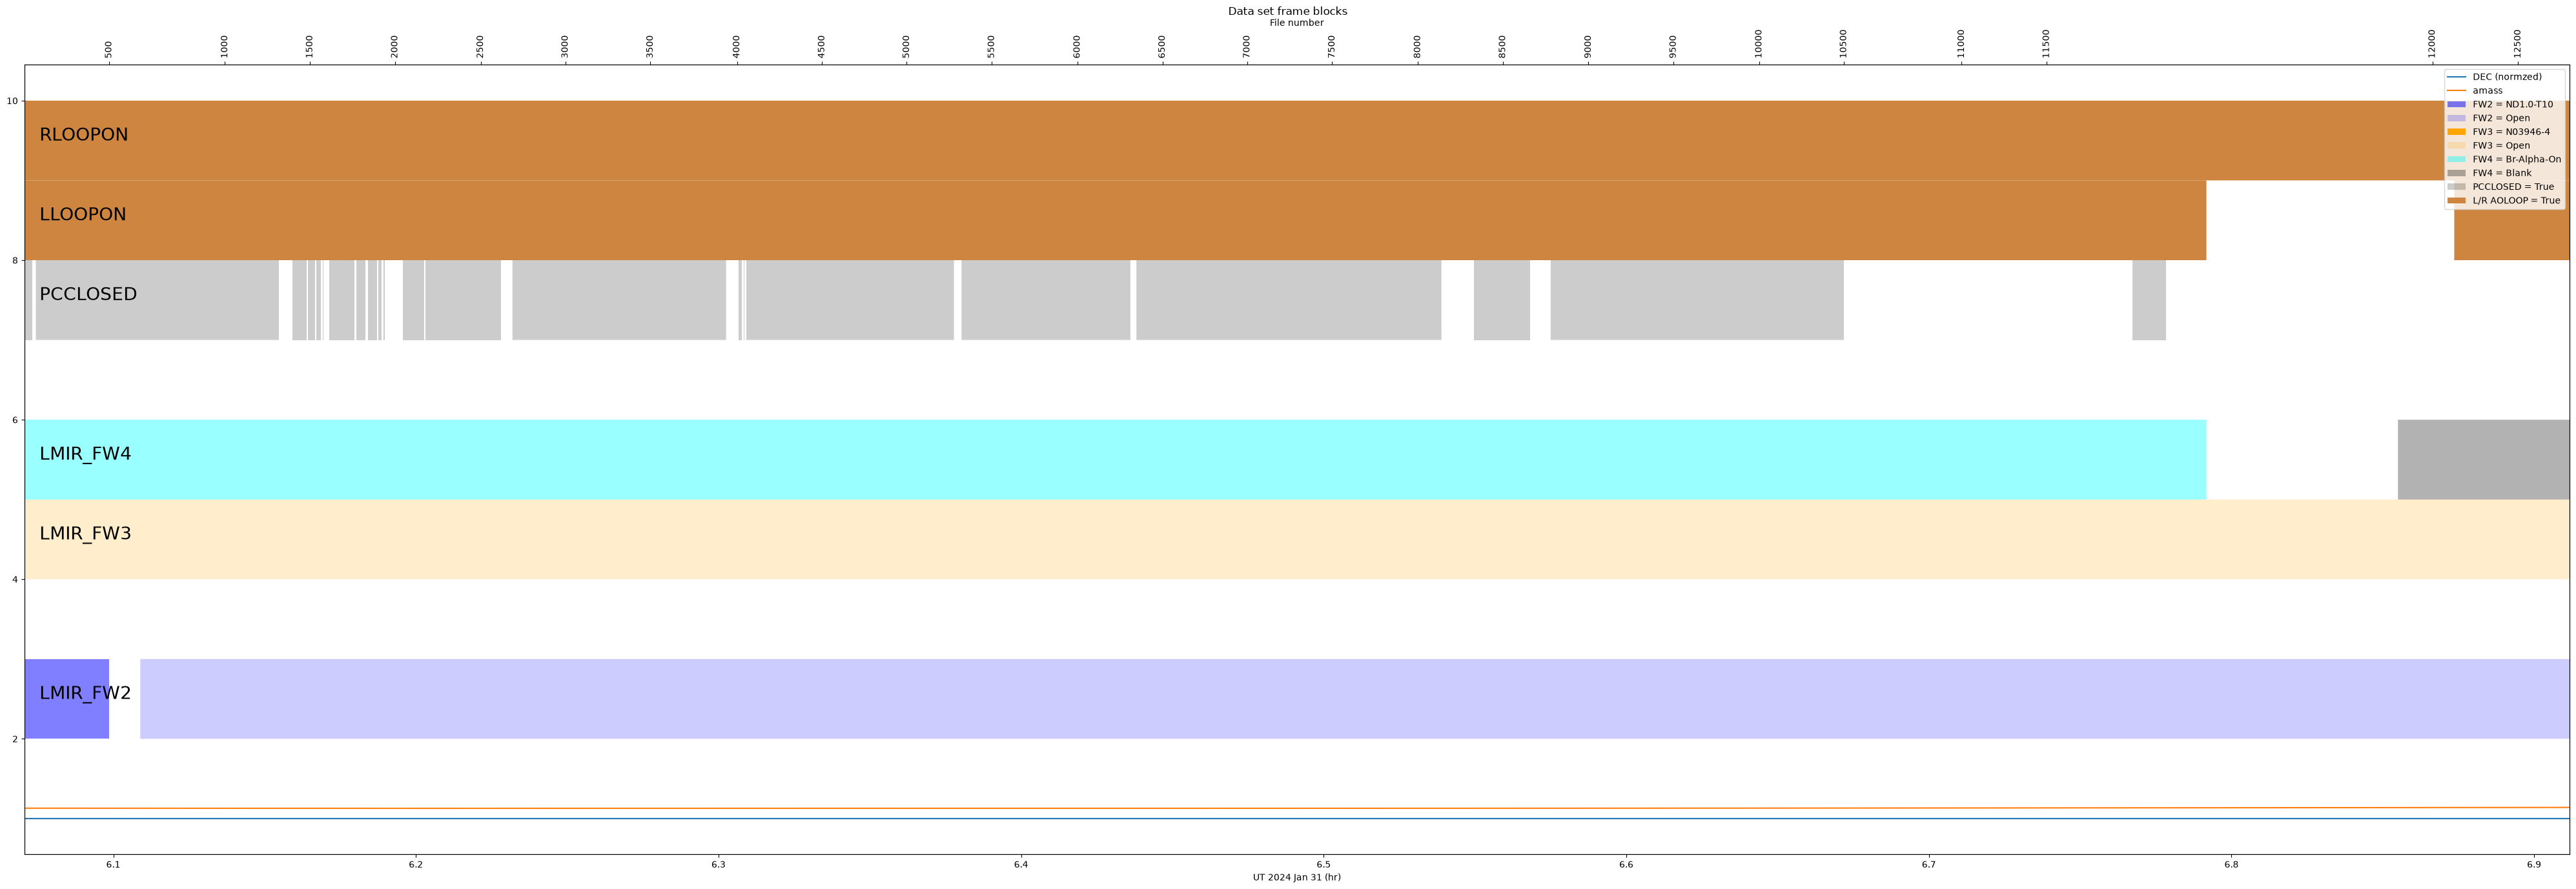

In [ ]:
fig, ax = plt.subplots()
fig.set_size_inches(40,14)

x_annot = df["LBT_UTC"].min() + 0.005

# plotted things
ax.plot(df["LBT_UTC"], np.divide(df["LBT_DEC"], np.max(df["LBT_DEC"])), label='DEC (normzed)')
ax.plot(df["LBT_UTC"], df["LBT_AIRM"], label='amass')


# LMIR FW2
ax.fill_between(df["LBT_UTC"], 2, 3, where=df["LMIR_FW2"]=="ND1.0-T10", \
                facecolor='blue', label='FW2 = ND1.0-T10', alpha=0.5)
ax.fill_between(df["LBT_UTC"], 2, 3, where=df["LMIR_FW2"]=="Open", \
                facecolor='blue', label='FW2 = Open', alpha=0.2)
ax.annotate('LMIR_FW2', xy=(x_annot, 2.5), size=20, xycoords='data')


# LMIR FW3
ax.fill_between(df["LBT_UTC"], 4, 5, where=df["LMIR_FW3"]=="N03946-4", \
                facecolor='orange', label='FW3 = N03946-4', alpha=1.0)
ax.fill_between(df["LBT_UTC"], 4, 5, where=df["LMIR_FW3"]=="Open", \
                facecolor='orange', label='FW3 = Open', alpha=0.2)
ax.annotate('LMIR_FW3', xy=(x_annot, 4.5), size=20, xycoords='data')


# LMIR FW4
ax.fill_between(df["LBT_UTC"], 5, 6, where=df["LMIR_FW4"]=="Br-Alpha-On", \
                facecolor='cyan', label='FW4 = Br-Alpha-On', alpha=0.4)
ax.fill_between(df["LBT_UTC"], 5, 6, where=df["LMIR_FW4"]=="Blank", \
                facecolor='black', label='FW4 = Blank', alpha=0.3)
ax.annotate('LMIR_FW4', xy=(x_annot, 5.5), size=20, xycoords='data')


# Phase controlled?
ax.fill_between(df["LBT_UTC"], 7, 8, where=df["PCCLOSED"]==1, \
                facecolor='black', label='PCCLOSED = True', alpha=0.2)
ax.annotate('PCCLOSED', xy=(x_annot, 7.5), size=20, xycoords='data')

# SX AO loop
ax.fill_between(df["LBT_UTC"], 8, 9, where=df["LLOOPON"]==1, \
                facecolor='peru', label='L/R AOLOOP = True', alpha=1)
ax.annotate('LLOOPON', xy=(x_annot, 8.5), size=20, xycoords='data')

# DX AO loop
ax.fill_between(df["LBT_UTC"], 9, 10, where=df["RLOOPON"]==1, \
                facecolor='peru', alpha=1)
ax.annotate('RLOOPON', xy=(x_annot, 9.5), size=20, xycoords='data')

ax.legend(loc='upper right', bbox_to_anchor=(1., 1))

plt.xlim([df["LBT_UTC"].min(), df["LBT_UTC"].max()])
plt.suptitle("Data set frame blocks")
plt.xlabel("UT 2024 Jan 31 (hr)")
add_framenum_axis(ax)
plt.tight_layout()

# save figure
#plt.savefig('block_diagram.png', bbox_inches='tight')

# ... or just show figure
plt.show()

# Display method 3: old-fashioned plotting

SEEING:
0.7656
1.1369
-----
AIRMASS:
1.1275
1.1351
-----
MM H2O:
3.5
8.96
-----
WINDSPEED (EXTERIOR):
0.5
3.1
-----
PARALLACTIC ANGLE CHANGE:
19.4771
-----


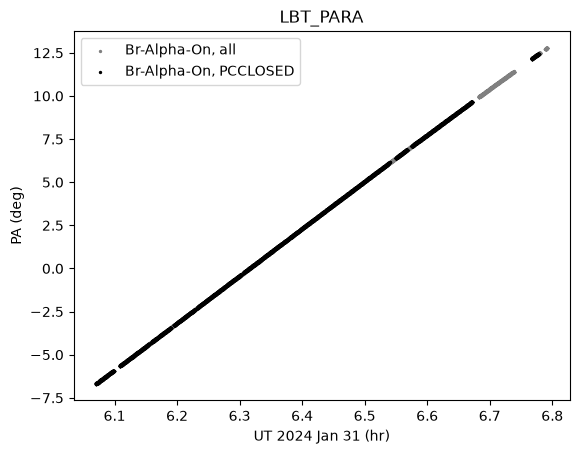

In [55]:
# for plotting

infoOfInterest_BrAlpha = df[np.logical_and(np.logical_and((df['FRAMENUM'] >= frame_sci_start), (df['FRAMENUM'] <= frame_sci_end) ), (df['LMIR_FW4'].astype(str) == 'Br-Alpha-On') )] # all procyon frames
infoOfInterest_BrAlpha_pc = infoOfInterest_BrAlpha[infoOfInterest_BrAlpha['PCCLOSED'] == 1] # phase-loop-closed procyon frames

darks = df[np.logical_and((df['FRAMENUM'] >= frame_dark_start), (df['FRAMENUM'] <= frame_dark_end) )] # darks

def print_range(label, series, scale=1.):
    series = scale * series.astype(float).where(series.astype(float) > 0)
    print(label)
    print(np.min(series))
    print(np.max(series))
    print('-----')

print_range('SEEING:', infoOfInterest_BrAlpha['SEEING'])
print_range('AIRMASS:', infoOfInterest_BrAlpha['LBT_AIRM'])
print_range('MM H2O:', infoOfInterest_BrAlpha['SMTTAU'], scale=20.)
print_range('WINDSPEED (EXTERIOR):', infoOfInterest_BrAlpha['WINDSPD'])
print('PARALLACTIC ANGLE CHANGE:')
print(np.subtract(np.max(infoOfInterest_BrAlpha['LBT_PARA'].astype(float)),
                  np.min(infoOfInterest_BrAlpha['LBT_PARA'].astype(float))))
print('-----')

plt.clf()
plt.scatter(infoOfInterest_BrAlpha['LBT_UTC'].astype(float),infoOfInterest_BrAlpha['LBT_PARA'].astype(float), color='gray', s=2, label='Br-Alpha-On, all')
plt.scatter(infoOfInterest_BrAlpha_pc['LBT_UTC'].astype(float),infoOfInterest_BrAlpha_pc['LBT_PARA'].astype(float), color='k', s=2, label='Br-Alpha-On, PCCLOSED')
plt.xlabel('UT 2024 Jan 31 (hr)')
plt.ylabel('PA (deg)')
plt.title('LBT_PARA')
plt.legend()
plt.savefig('pa_procyon.png')
#plt.show()

In [45]:
print(len(infoOfInterest_BrAlpha))
print(len(infoOfInterest_BrAlpha_pc))
print(len(darks))

11800
9877
1000


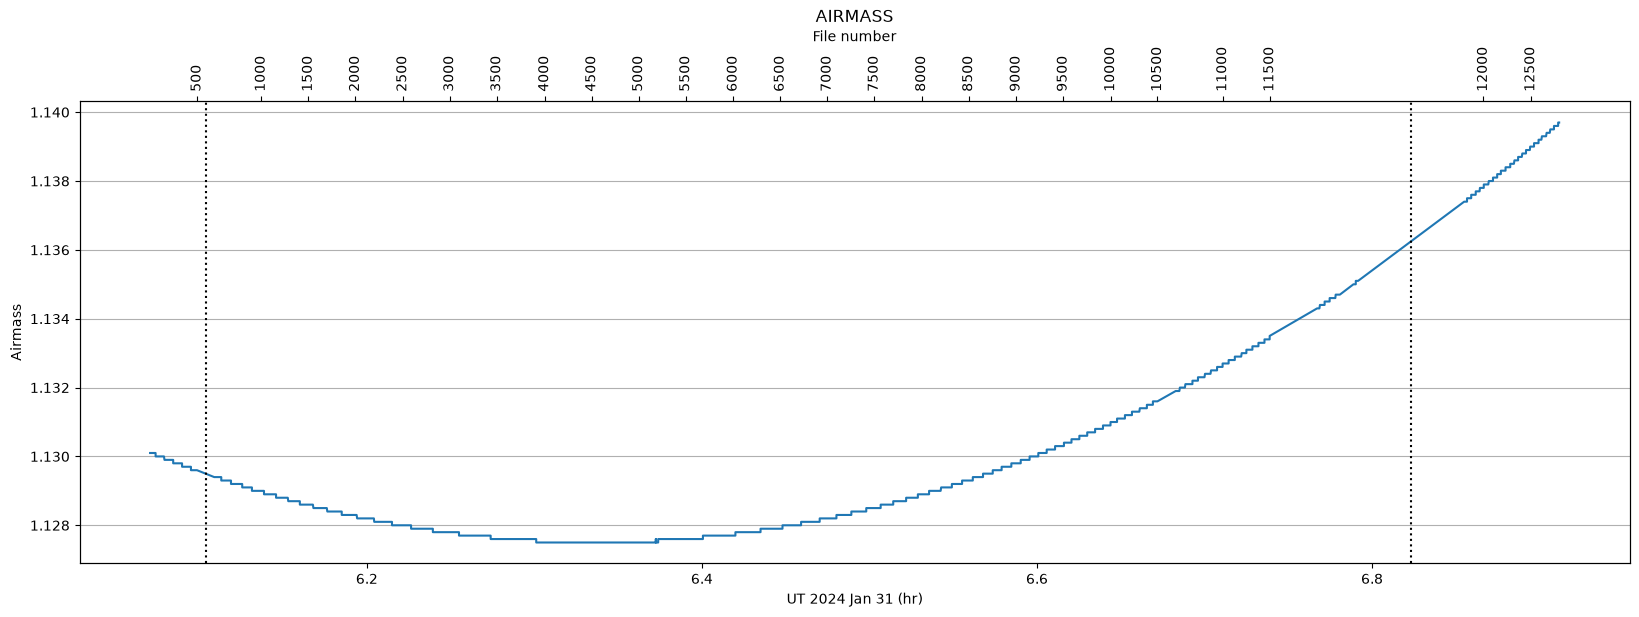

In [ ]:
# AIRMASS

fig, ax = plt.subplots(figsize=(20, 6))
plt.plot(df['LBT_UTC'], df['LBT_AIRM'].astype(float))
mark_blocks(ax)
plt.grid(axis='y')
plt.xlabel('UT 2024 Jan 31 (hr)')
plt.ylabel('Airmass')
plt.title('AIRMASS')
add_framenum_axis(ax)
#plt.savefig('airmass_procyon.png')
plt.show()

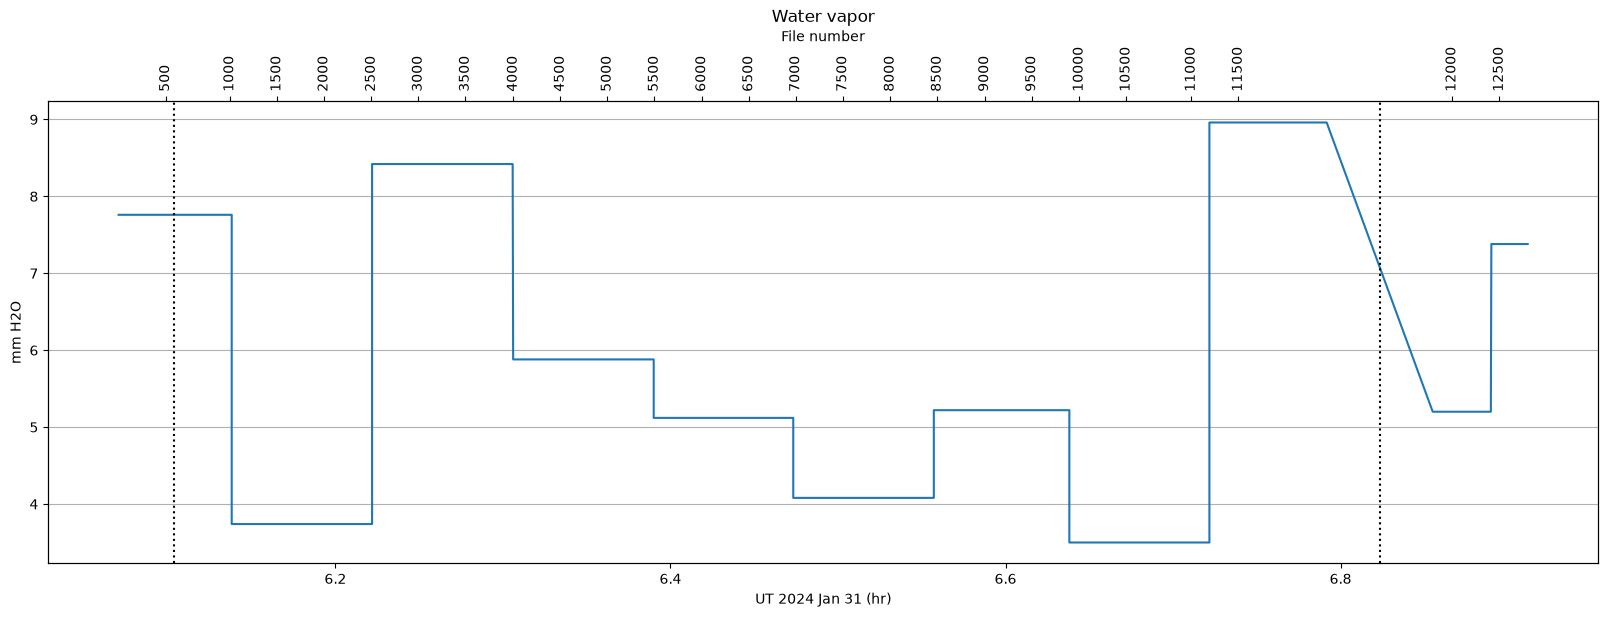

In [ ]:
# mm H2O

fig, ax = plt.subplots(figsize=(20, 6))
plt.plot(df['LBT_UTC'], 20.*df['SMTTAU'].astype(float))
mark_blocks(ax)
plt.grid(axis='y')
plt.xlabel('UT 2024 Jan 31 (hr)')
plt.ylabel('mm H2O')
plt.title('Water vapor')
add_framenum_axis(ax)
#plt.savefig('water_vapor_procyon.png')
plt.show()

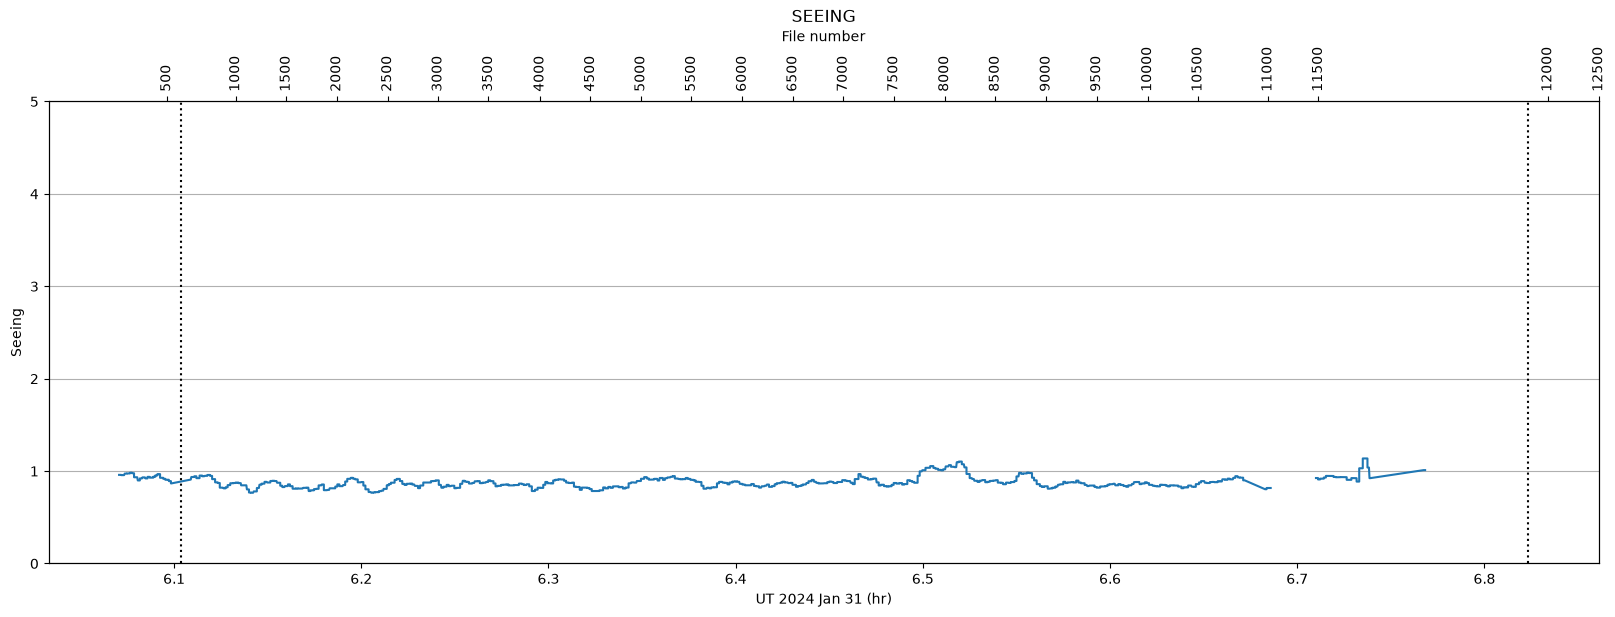

In [ ]:
# SEEING (values <= 0 are missing data)

fig, ax = plt.subplots(figsize=(20, 6))
plt.plot(df['LBT_UTC'], df['SEEING'].astype(float).where(df['SEEING'].astype(float) > 0))
mark_blocks(ax)
plt.grid(axis='y')
plt.ylim([0,5])
plt.xlabel('UT 2024 Jan 31 (hr)')
plt.ylabel('Seeing')
plt.title('SEEING')
add_framenum_axis(ax)
#plt.savefig('seeing_procyon.png')
plt.show()

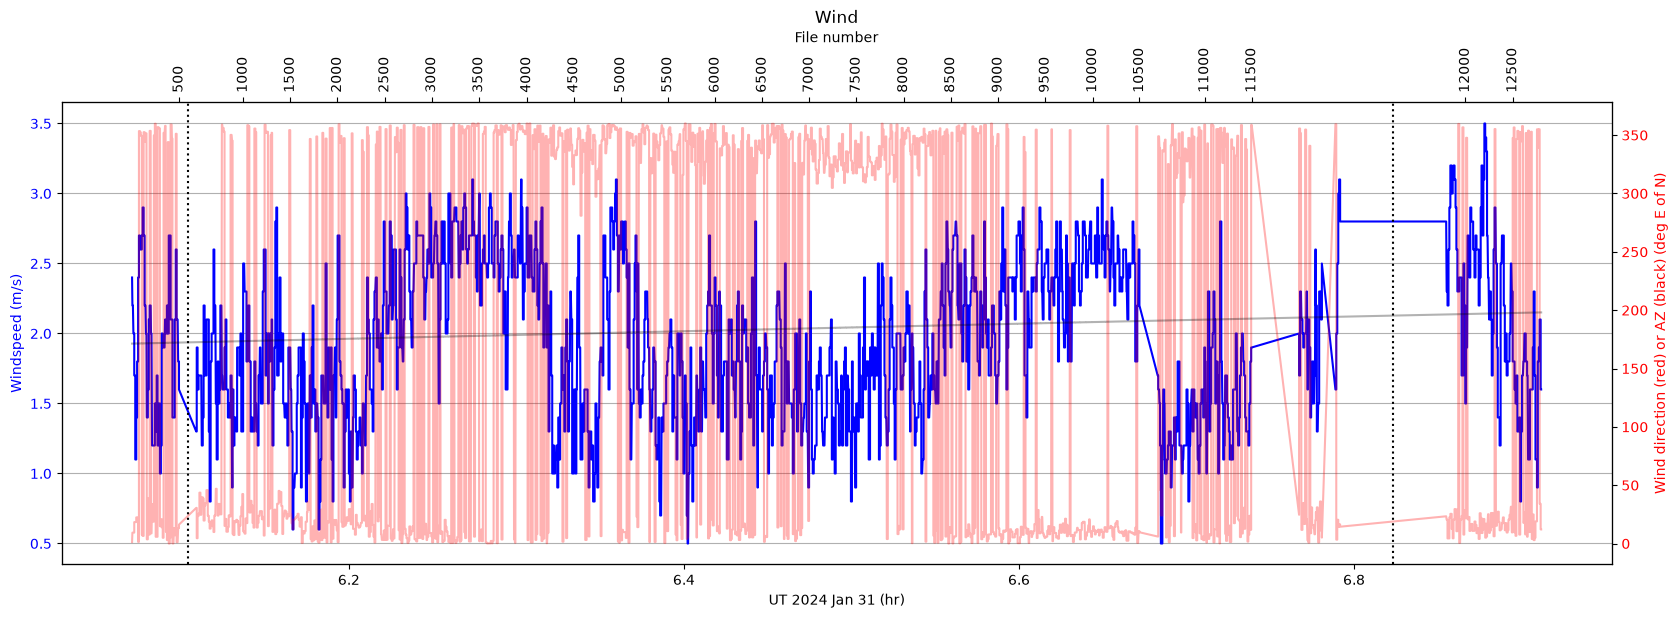

In [ ]:
# WINDDIR AND WINDSPEED

fig, ax1 = plt.subplots(figsize=(20, 6))
ax2 = ax1.twinx()

ax1.plot(df['LBT_UTC'], df['WINDSPD'].astype(float), color='blue')
ax2.plot(df['LBT_UTC'], df['WINDDIR'].astype(float), color='red', alpha=0.3)
ax2.plot(df['LBT_UTC'], df['LBT_AZ'].astype(float), color='k', alpha=0.3)

ax1.set_xlabel('UT 2024 Jan 31 (hr)')
ax1.set_ylabel('Windspeed (m/s)', color='blue')
ax2.set_ylabel('Wind direction (red) or AZ (black) (deg E of N)', color='red')

ax1.tick_params(axis='y', labelcolor='blue')
ax2.tick_params(axis='y', labelcolor='red')

mark_blocks(ax1)
ax1.grid(axis='y')

ax1.set_title('Wind')
add_framenum_axis(ax1)
#plt.savefig('wind_procyon.png')
plt.show()

In [50]:
quantity_of_interest = df['SEEING'].where(np.logical_and(df['SEEING'].astype(float) > 0.001, np.logical_and(df['FRAMENUM'] >= frame_sci_start, df['FRAMENUM'] <= frame_sci_end))) # PROCYON
#quantity_of_interest = df['SEEING'].where(np.logical_and(df['SEEING'].astype(float) > 0.001, np.logical_and(df['FRAMENUM'] >= frame_dark_start, df['FRAMENUM'] <= frame_dark_end))) # DARKS

print(np.mean(quantity_of_interest))
print(np.std(quantity_of_interest))
print(np.min(quantity_of_interest))
print(np.max(quantity_of_interest))

0.8795054614275414
0.058592076190445
0.7656
1.1369


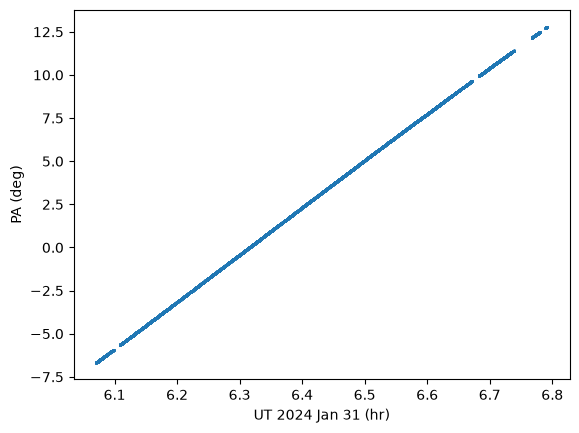

In [51]:
# PA

plt.plot(infoOfInterest_BrAlpha['LBT_UTC'], infoOfInterest_BrAlpha['LBT_PARA'], linestyle='None', marker='o', markersize=1)
plt.xlabel('UT 2024 Jan 31 (hr)')
plt.ylabel('PA (deg)')
plt.show()

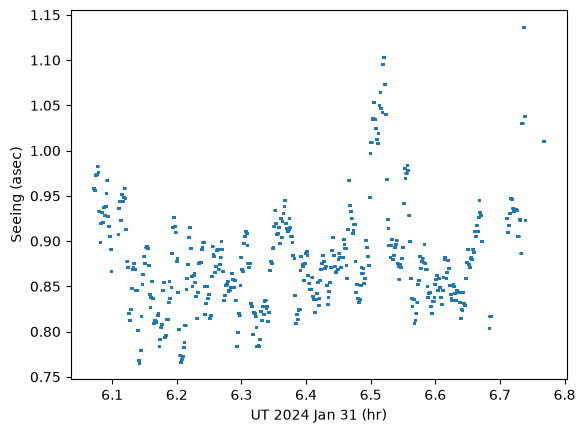

In [52]:
# Seeing

plt.plot(infoOfInterest_BrAlpha['LBT_UTC'], infoOfInterest_BrAlpha['SEEING'].where(infoOfInterest_BrAlpha['SEEING'] > 0), linestyle='None', marker='o', markersize=1)
plt.xlabel('UT 2024 Jan 31 (hr)')
plt.ylabel('Seeing (asec)')
plt.show()